## Profile likelihood for the Gamma parameters $(a, b)$ at known vertex and axis

**Known per event:** vertex $\mathbf v$, axis $\hat{\mathbf u}$ (both from the track fit in `profile_params.csv`), $t_v = 0$.
**Data:** photoelectron counts $n_{dk}$ of module $d$ (positions $\mathbf R_d$) in time bin $k$, $\tau_k = k\,\Delta t$, $\Delta t = 3$ ns, $k = 0,\dots,50$ (hits after 150 ns are not used).
**Free:** the longitudinal profile $g(s; a, b)$; the light scale (energy) is profiled out.

**1. Emission points.** Depth grid $s_i = (i + \tfrac12)\Delta s$, $\Delta s = 0.1$ m, $s_i < 15$ m:
$$\mathbf r_i = \mathbf v + s_i\,\hat{\mathbf u},\qquad \mathbf d_{id} = \mathbf R_d - \mathbf r_i,\qquad D_{id} = |\mathbf d_{id}|,\qquad \cos\psi_{id} = \frac{\mathbf d_{id}\cdot\hat{\mathbf u}}{D_{id}} .$$

**2. Light per unit profile** (smeared Cherenkov cone with a 5 % isotropic floor, absorption, $1/D^2$):
$$\Lambda_{id} = \Big[\exp\!\Big(-\frac{(\cos\psi_{id} - \cos\theta_c)^2}{2 w^2}\Big) + 0.05\Big]\,\frac{e^{-D_{id}/\lambda_a}}{D_{id}^2},
\qquad \cos\theta_c = \tfrac{1}{1.33},\ w = 0.15,\ \lambda_a = 50\ \text{m}.$$

**3. Arrival time.** Unscattered arrival $t^0_{id} = s_i/c + n_g D_{id}/c$ ($c = 0.2998$ m/ns, $n_g = 1.35$); the measured time is $T = t^0 + G + X$ with $G \sim \mathcal N(0, \sigma_t^2)$ (PMT jitter) and $X \sim \mathrm{Exp}$ with mean $\tau$ (scattering delay), $\sigma_t = \tau = 0.5$ ns. $T - t^0$ is exponentially modified Gaussian (`scipy.stats.exponnorm`, $K = \tau/\sigma_t$, scale $\sigma_t$):
$$F(x) = \Phi\!\Big(\frac{x}{\sigma_t}\Big) - \exp\!\Big(-\frac{x}{\tau} + \frac{\sigma_t^2}{2\tau^2}\Big)\,\Phi\!\Big(\frac{x}{\sigma_t} - \frac{\sigma_t}{\tau}\Big),
\qquad P_{idk} = F(\tau_{k+1} - t^0_{id}) - F(\tau_k - t^0_{id}).$$

**4. Kernel** (light per unit profile at depth $s_i$, in module $d$, time bin $k$): $\;K_{idk} = \Lambda_{id}\,P_{idk}$. It depends only on $(\mathbf v, \hat{\mathbf u})$, so it is computed once per event.

**5. Profile and its parametrisation.**
$$g(s; a, b) = \frac{s^{a-1} e^{-s/b}}{\Gamma(a)\,b^a},\qquad m = ab\ \text{(mean depth)},\quad \sigma = \sqrt a\,b\ \text{(width)},\qquad a = \Big(\frac m\sigma\Big)^2,\quad b = \frac{\sigma^2}{m},$$
fitted in $\mathbf p = (\ln m, \ln\sigma)$, which is far less degenerate than $(a, b)$.

**6. Expected counts.** Per unit light scale, and with the scale $E$ fixed at its maximum-likelihood value $\hat E = N/\sum_{dk} M_{dk}$ ($N = \sum_{dk} n_{dk}$):
$$M_{dk}(a, b) = \sum_i g(s_i; a, b)\,\Delta s\,K_{idk},\qquad \mu_{dk} = \hat E\,M_{dk} = N\,\frac{M_{dk}}{\sum_{d'k'} M_{d'k'}} .$$

**7. Poisson likelihood** (constants $\ln n_{dk}!$ dropped):
$$-\ln L(a, b) = \sum_{dk}\big[\mu_{dk} - n_{dk}\ln\mu_{dk}\big].$$
Since $\sum_{dk}\mu_{dk} = N$ is fixed, this equals $-\sum_{dk} n_{dk}\ln\big(M_{dk}/\textstyle\sum M\big) + \text{const}$: a multinomial in the shape of the light pattern. The total charge carries no information on $(a, b)$ once $E$ is free.

**8. Fit.** $\hat{\mathbf p} = \arg\min\,[-\ln L]$ by L-BFGS-B within $m \in [0.3, 8]$ m, $\sigma \in [0.2, 4]$ m, from three starts $(m, \sigma) = (1.5, 1.0), (3.0, 1.5), (1.0, 0.5)$ m, keeping the best. A fit at a bound means the likelihood kept rising towards the edge.

**9. Uncertainty.** The contours of $-\Delta\ln L = -\ln L + \ln L_{\min}$ in the $(m, \sigma)$ plane are the confidence regions: for the two parameters jointly $-\Delta\ln L = 1.15,\ 3.09,\ 5.92$ enclose 68.3 %, 95.4 % and 99.7 %; the levels 0.5, 2, 4.5 drawn below are the $1, 2, 3\,\sigma$ intervals of a single parameter with the other profiled. Equivalently $\mathrm{Cov}(\hat{\mathbf p}) \approx [\nabla^2_{\mathbf p}(-\ln L)]^{-1}$ at the minimum.

The kernel constants are a hand-set analytic model, not tuned to OMSim; a mismatch shows up as biased $(a, b)$ even where the fit is well constrained.

136 usable events, e.g. [18, 6, 15, 37, 19, 42, 33, 39, 51, 0]
event 191: 2690 hits | fit a=2.54, b=1.48 (m=3.75 m) | truth a=2.57, b=1.34 (m=3.43 m)


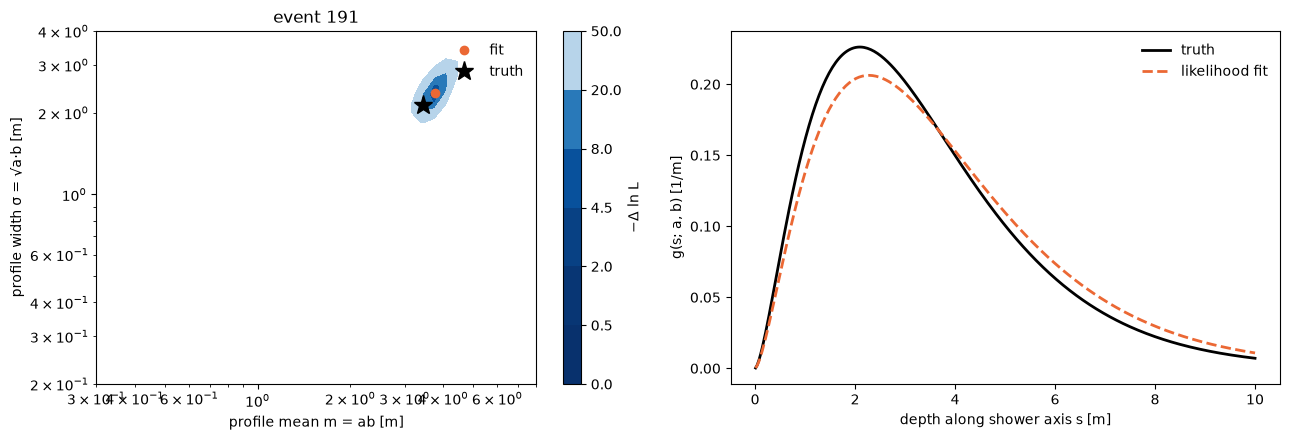

In [3]:


from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, uproot
from scipy.optimize import minimize
from scipy.special import gammaln
from scipy.stats import exponnorm

BASE = Path("."); RUN = BASE / "nue_nc_multidom"
doms  = pd.DataFrame(json.loads((RUN / "part_0000_doms.json").read_text())).set_index("moduleID")[["x", "y", "z"]]
R_DOM = doms.to_numpy(float)
hits  = pd.DataFrame(uproot.open(RUN / "part_0000_hits.root")["PhotonHits"].arrays(["eventID", "hitTime", "moduleID"], library="np"))
pp    = pd.read_csv(RUN / "part_0000_profile_params.csv").set_index("eventID")   # truth: vertex, axis u, a, b

DT = 3.0;  T_EDGES = np.arange(0, 150 + DT, DT)   
DS = 0.1;  S = np.arange(DS / 2, 15, DS)           
C, N_G, COS_C = 0.2998, 1.35, 1 / 1.33
LAM_A, SIG_T, TAU, W_ANG = 50.0, 0.5, 0.5, 0.15     

def gamma_pdf(s, a, b):
    return np.exp((a - 1) * np.log(s) - s / b - gammaln(a) - a * np.log(b))

def kernel(v, u):
    """K[s, dom, t]: expected light per unit profile at depth s, for each DOM and time bin."""
    r = v + S[:, None] * u
    d = R_DOM[None] - r[:, None]; D = np.linalg.norm(d, axis=2)
    cos = (d @ u) / D
    amp = (np.exp(-0.5 * ((cos - COS_C) / W_ANG) ** 2) + 0.05) * np.exp(-D / LAM_A) / D**2
    t0 = S[:, None] / C + N_G * D / C                             
    cdf = exponnorm.cdf(T_EDGES - t0[..., None], TAU / SIG_T, scale=SIG_T)
    return amp[..., None] * np.diff(cdf, axis=2)

def counts(eid):
    h = hits[hits.eventID == eid]; n = np.zeros((len(doms), len(T_EDGES) - 1))
    for m, g in h.groupby("moduleID"): n[m], _ = np.histogram(g.hitTime, T_EDGES)
    return n

def to_ab(p):                                  
    m, sig = np.exp(p); return (m / sig) ** 2, sig**2 / m

def nll(p, K, n):                            
    a, b = to_ab(p)
    M  = np.tensordot(gamma_pdf(S, a, b) * DS, K, axes=1) + 1e-12
    mu = M * n.sum() / M.sum()
    return (mu - n * np.log(mu)).sum()

BOUNDS = [(np.log(0.3), np.log(8)), (np.log(0.2), np.log(4))]      

def fit(eid):
    r = pp.loc[eid]
    K, n = kernel(r[["vx", "vy", "vz"]].to_numpy(float), r[["ux", "uy", "uz"]].to_numpy(float)), counts(eid)
    starts = np.log([[1.5, 1.0], [3.0, 1.5], [1.0, 0.5]])
    best = min((minimize(nll, x0, args=(K, n), method="L-BFGS-B", bounds=BOUNDS) for x0 in starts), key=lambda o: o.fun)
    return best, K, n

nhits = hits.eventID.value_counts()
ok_ids = [e for e in pp.index if nhits.get(e, 0) >= 20]     # has a truth fit AND ≥ 20 hits
print(f"{len(ok_ids)} usable events, e.g. {ok_ids[:10]}")
EID = 191
best, K, n = fit(EID); a, b = to_ab(best.x); r = pp.loc[EID]
print(f"event {EID}: {int(n.sum())} hits | fit a={a:.2f}, b={b:.2f} (m={a*b:.2f} m) | truth a={r.a_mle:.2f}, b={r.b_mle:.2f} (m={r.a_mle*r.b_mle:.2f} m)")

lm, ls = np.meshgrid(np.linspace(*BOUNDS[0], 40), np.linspace(*BOUNDS[1], 40))
L = np.array([[nll([x, y], K, n) for x, y in zip(rx, ry)] for rx, ry in zip(lm, ls)])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
cs = ax[0].contourf(np.exp(lm), np.exp(ls), L - L.min(), levels=[0, 0.5, 2, 4.5, 8, 20, 50], cmap="Blues_r")
fig.colorbar(cs, ax=ax[0], label="−Δ ln L")
ax[0].plot(*np.exp(best.x), "o", color="#eb6834", label="fit")
ax[0].plot(r.a_mle * r.b_mle, np.sqrt(r.a_mle) * r.b_mle, "*", ms=14, color="black", label="truth")
ax[0].set(xscale="log", yscale="log", xlabel="profile mean m = ab [m]", ylabel="profile width σ = √a·b [m]", title=f"event {EID}")
ax[0].legend(frameon=False)
ss = np.linspace(0.01, 10, 300)
ax[1].plot(ss, gamma_pdf(ss, r.a_mle, r.b_mle), color="black", lw=2, label="truth")
ax[1].plot(ss, gamma_pdf(ss, a, b), color="#eb6834", lw=2, ls="--", label="likelihood fit")
ax[1].set(xlabel="depth along shower axis s [m]", ylabel="g(s; a, b) [1/m]"); ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()


In [4]:

def summary(x):
    q16, q50, q84 = np.percentile(x, [16, 50, 84])
    return dict(N=len(x), median=q50, sig68=0.5 * (q84 - q16), q16=q16, q84=q84)

SEL = {"all": np.ones(len(res), bool), "not at bound": ok.to_numpy()}
stats = pd.DataFrame({(LAB[k], s): summary(res[k][m]) for k in ["da", "db"] for s, m in SEL.items()}).T
print(stats.round(2))

NAME = {"da": "a", "db": "b"}
fig, ax = plt.subplots(2, 2, figsize=(11, 8.5), gridspec_kw=dict(height_ratios=[1, 1.2]))
for j, k in enumerate(["da", "db"]):
    x, c = res[k].to_numpy(), COL[k]
    lim = np.ceil(np.abs(x).max()); bins = np.linspace(-lim, lim, 41)
    h = ax[0, j]
    for s, alpha, kw in [("all", 0.45, dict(color=c, alpha=0.3, lw=0)), ("not at bound", 1.0, dict(histtype="step", lw=1.5, color=c))]:
        st = summary(x[SEL[s]])
        h.hist(x[SEL[s]], bins=bins, label=f"{s}:  N={st['N']},  median {st['median']:+.2f},  σ68 {st['sig68']:.2f}", **kw)
    ymax = h.get_ylim()[1]
    for s, y, alpha in [("not at bound", 1.06, 1.0), ("all", 1.18, 0.45)]:       # 16-84 % interval bars
        st = summary(x[SEL[s]])
        h.errorbar(st["median"], y * ymax, xerr=[[st["median"] - st["q16"]], [st["q84"] - st["median"]]],
                   fmt="o", ms=5, capsize=3, lw=1.5, color=c, alpha=alpha)
    h.axvline(0, color="#777", lw=1)
    h.set(xlabel=LAB[k], ylabel="events", title=f"residual of {NAME[k]}", ylim=(0, 1.55 * ymax))
    h.legend(frameon=False, fontsize=8.5, loc="upper left"); h.spines[["top", "right"]].set_visible(False)
    p = ax[1, j]
    t, f = res[f"{NAME[k]}_true"], res[f"{NAME[k]}_fit"]
    r = np.array([min(t.min(), f.min()), max(t.max(), f.max())]) * [0.6, 1.7]
    p.plot(r, r, color="#777", lw=1); p.fill_between(r, r / 2, r * 2, color="#777", alpha=0.08, lw=0)
    p.scatter(t[ok], f[ok], s=18, color=c, alpha=0.8, lw=0, label="not at bound")
    p.scatter(t[~ok], f[~ok], s=18, facecolor="none", edgecolor=c, lw=1, label="at bound")
    p.set(xscale="log", yscale="log", xlim=r, ylim=r, xlabel=f"{NAME[k]} truth", ylabel=f"{NAME[k]} fit",
          title=f"{NAME[k]}: fit vs truth (grey band = factor 2)")
    p.legend(frameon=False, fontsize=9, loc="upper left"); p.spines[["top", "right"]].set_visible(False)
for a_ in ax.ravel(): a_.grid(color="#eee", lw=0.8); a_.set_axisbelow(True)
plt.tight_layout(); plt.show()


NameError: name 'res' is not defined